# persistance/03 — obstacle robustness *(behaviour, oracle-judged)*

How robust is Qwen2.5-Coder-32B-Instruct when its frontier line is **forced to start with a misleading
prefix**? For each sub-goal g_k we append a hand-curated *escapable* obstacle after the `{var} =` pivot,
greedy-generate the rest of the line, and a bespoke oracle (`obstacle_eval.judge_adapts`) grades the full
right-hand side: **ADAPTED** (implements g_k, working around the forced stub — any valid impl, so it
honours plasticity), **SUCCUMBED** (followed the stub to the wrong op), **ESCAPED** (reaches g_k but by
degenerately discarding the stub), **BROKEN** (invalid/incomplete).

Two difficulty levels: **easy** (ignorable identities — `True and`, `0 +`, `(`) and **hard** (forced
wrong sibling `((wrong)` or a wrong-op fragment `- 1 +`). `aligned` = correct start (ceiling control).
Prefills: `scripts/evaluation/obstacle_prefills.py` (all 64 predicates, escapability-verified).

In [1]:
%load_ext autoreload
%autoreload 2
import os, sys, re, json, random, logging
sys.path.append("../..")
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "4,5")   # 32B ~63GB; set to a free GPU
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import numpy as np
import matplotlib.pyplot as plt
import torch
from rich.console import Console, Group
from rich.theme import Theme
from rich.table import Table
from rich.panel import Panel
from rich.text import Text
from rich.box import SIMPLE_HEAVY
from rich.markup import escape
from src.utils import logging_utils, env_utils
os.chdir(env_utils.PROJECT_ROOT); sys.path.insert(0, env_utils.PROJECT_ROOT)   # anchor CWD+imports to repo root
logging_utils.configure(level=logging.INFO)
console = Console(theme=Theme({"default": "white"}), highlight=False)
def rich_print(*a, **k): console.print(*a, **k)

## 0. Model

In [2]:
from src.models import ModelandTokenizer
MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"
mt = ModelandTokenizer(model_key=MODEL_NAME, dtype=torch.bfloat16,
                       device_map="auto", attn_implementation="eager")
print("loaded", MODEL_NAME)

2026-09-20 19:55:49 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory: /disk/u/models
2026-09-20 19:55:49 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-09-20 19:55:49 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/config.json "HTTP/1.1 200 OK"
2026-09-20 19:55:49 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-09-20 19:55:49 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/config.json "HTTP/1.1 200 OK"
2026-09-20 19:55:49 httpx INFO     HTTP Re

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-09-20 19:56:13 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/generation_config.json "HTTP/1.1 307 Temporary Redirect"
2026-09-20 19:56:13 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/generation_config.json "HTTP/1.1 200 OK"
2026-09-20 19:56:13 src.models INFO     loaded model <Qwen/Qwen2.5-Coder-32B-Instruct> | size: 62492.135 MB | dtype: torch.bfloat16 | device: cuda:0
loaded Qwen/Qwen2.5-Coder-32B-Instruct


## 1. Corpus + obstacle prompts

A **minimal single-predicate prompt** per predicate: signature + a one-item task list, ending at the
frontier `    a =`. We append an obstacle prefix after the `=`, greedy-generate the rest of the line,
and take the full right-hand side.

In [3]:
import src.diff.data as D
from scripts.evaluation.eval_goalscope import _chat_prompt, greedy_continue
from scripts.evaluation.obstacle_prefills import OBSTACLE_PREFILLS, ARG
from scripts.evaluation.obstacle_eval import judge_adapts
from src.tokens import prepare_input

def build_obstacle_prompt(dt, pid, prefix):
    """(prompt, target_predicate). TWO listed conditions with the FIRST PREFILLED: signature +
    `(1) ctx (2) target` + `    a = <ctx impl>` (prior sub-goal, done) + `    b =` + prefix. The obstacle
    is applied at the SECOND condition `b =` — the frontier we probe/judge (the target = `pid`)."""
    bank = D.QTASKS[dt]; arg = ARG[dt]
    preds = list(bank.predicates)
    idx = next(i for i, x in enumerate(preds) if x.id == pid)
    target = preds[idx]
    ctx = preds[(idx + 2) % len(preds)]                       # a different prior sub-goal
                                                              # (offset 2 avoids the auto-picked obstacle sibling at idx+1)
    q = D._question([ctx.description, target.description], dt, arg, "python", "listed")
    sig = D._signature(dt, arg, "python")
    first = D._assign_line(ctx, arg, "python", res_name="a")  # prefilled `    a = <ctx impl>`
    base = "<code>\n" + sig + "\n" + first + "\n    b ="     # frontier = 2nd condition `b =`
    return _chat_prompt(mt, q, base) + prefix, target

@torch.no_grad()
def run_obstacle(dt, pid, prefix, max_new=48):
    """Greedy-continue after the forced prefix; return (rhs, prompt, gen). rhs = full first-line RHS."""
    prompt, p = build_obstacle_prompt(dt, pid, prefix)
    inp = prepare_input(prompts=prompt, tokenizer=mt)
    gen = greedy_continue(mt, **inp, max_new_tokens=max_new)
    rhs = (prefix + gen).split("\n")[0].strip()          # everything after `b =`, first line
    return rhs, prompt, gen, p

# smoke: one easy + one hard on int/is_even (no oracle call yet)
_r, _pr, _g, _p = run_obstacle("int", "is_even", OBSTACLE_PREFILLS["int"]["is_even"]["hard"][0])
print("hard[0] stub :", OBSTACLE_PREFILLS["int"]["is_even"]["hard"][0])
print("RHS          :", _r)


# ── GoalScope read-out at the last prompt token (for eyeballing; NOT judged) ──
from scripts.evaluation.eval_goalscope import load_json_heads
from src.goals.goalscope import apply_goalscope
_HEADS = f"head_sets/{MODEL_NAME.split('/')[-1]}/goal_topk/goal__lam20_top250.json"
goal_heads = load_json_heads(_HEADS, mt.n_layer, mt.n_heads)
GS = dict(selected_heads=goal_heads, strategy="additive_norm", alpha=0.1,
          steer_layer_range=(35, 46), n_steer_tokens="all", max_new_tokens=48)

@torch.no_grad()
def readout_at(prompt):
    """GoalScope NL verbalization at the LAST token of `prompt` (single-shot; not judged)."""
    inp = prepare_input(prompts=prompt, tokenizer=mt)
    pos = inp.input_ids.shape[1] - 1
    r = apply_goalscope(inp, mt=mt, show=False, include_noncode=False, token_positions=[pos], **GS)
    return (r[0].get("patched_gen") or "").strip() if r else ""


hard[0] stub :  (((n > 0))
RHS          : (((n > 0)) and (n % 2 == 0)) or ((n < 0) and (n % 2 == 0))


## 2. Vibe-check — a few examples per level (with oracle verdict)

Panels: the appended obstacle, the full RHS the model produced, and the `judge_adapts` verdict. Look for
whether hard obstacles get ADAPTED (robust) vs SUCCUMBED (broke).

In [4]:
def show_example(dt, pid, level, k=0):
    spec = OBSTACLE_PREFILLS[dt][pid]
    prefix = spec[level][k]
    rhs, prompt, gen, p = run_obstacle(dt, pid, prefix)       # perturbed prompt ends at `b =` + prefix
    _, clean_prompt, clean_gen, _ = run_obstacle(dt, pid, "") # clean prompt ends at `b =` (NOT judged)
    ro_clean = readout_at(clean_prompt)                        # GoalScope @ last token (the `=` pivot)
    ro_obs   = readout_at(prompt)                              # GoalScope @ last token (end of prefix)
    v = judge_adapts(p.description, prefix, rhs)
    color = {"ADAPTED":"sea_green3","ESCAPED":"yellow","SUCCUMBED":"salmon1","BROKEN":"grey58"}.get(v["verdict"],"white")
    gen_line   = gen.split("\n")[0]
    clean_line = clean_gen.split("\n")[0]
    body = (
        f"[bold]{escape(dt)} · {escape(pid)}[/bold]  [grey58]({level})[/grey58]\n"
        f"[grey58]sub-goal:[/grey58] {escape(p.description)}\n"
        f"[grey58]── full prompt (clean, ends at `b =`; obstacle appends the [salmon1]salmon[/salmon1]) ──[/grey58]\n"
        f"[white]{escape(clean_prompt)}[/white][salmon1]{escape(prefix)}[/salmon1]\n"
        f"[grey58]── GoalScope read-out @ last prompt token (not judged) ──[/grey58]\n"
        f"[grey58]clean pivot (`=`):[/grey58] [sea_green3]{escape(ro_clean)}[/sea_green3]\n"
        f"[grey58]obstacle pivot   :[/grey58] [salmon1]{escape(ro_obs)}[/salmon1]\n"
        f"[grey58]── generation ──[/grey58]\n"
        f"[grey58]clean   :[/grey58] [grey58]b =[/grey58][sea_green3]{escape(clean_line)}[/sea_green3]\n"
        f"[grey58]obstacle:[/grey58] [grey58]b =[/grey58][salmon1]{escape(prefix)}[/salmon1][bright_yellow]{escape(gen_line)}[/]\n"
        f"[grey58]verdict :[/grey58] [{color}]{v['verdict']}[/{color}] — {escape(v['rationale'])}"
    )
    rich_print(Panel(Text.from_markup(body), border_style="grey42", padding=(0,1)))

# 4 easy + 4 hard across datatypes
# picks = [("int","is_even"), ("str","has_digit"), ("list[int]","has_even"), ("list[str]","count_long")]
picks = [
    ("list[str]", "has_palindrome"), 
    ("list[str]", "total_length"), 
    ("list[str]", "count_starts_vowel"),
    ("list[str]", "longest_word_length"),
    ("list[str]", "total_vowels")
]
for lvl in ("easy","hard"):
    rich_print(f"[bold underline]{lvl.upper()}[/bold underline]  [grey58](salmon = forced prefix · yellow = LM continuation · green = clean/unperturbed)[/grey58]")
    for dt, pid in picks:
        show_example(dt, pid, lvl, k=0)


EASY  (salmon = forced prefix · yellow = LM continuation · green = clean/unperturbed)

GoalScope[additive_norm]:   0%|          | 0/1 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
You have set `compile_config`, but we are unable to meet the criteria for compilation. Compilation will be skipped.


GoalScope[additive_norm]:   0%|          | 0/1 [00:00<?, ?it/s]

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ list[str] · has_palindrome  (easy)                                                                              │
│ sub-goal: whether any word is a palindrome                                                                      │
│ ── full prompt (clean, ends at `b =`; obstacle appends the salmon) ──                                           │
│ <|im_start|>system                                                                                              │
│ You are a helpful assistant proficient in programming. Always wrap your code inside <code></code> blocks. Just  │
│ the code, no need to comment or explain.<|im_end|>                                                              │
│ <|im_start|>user                                                                                                │
│ Write a Python program that implements a function `func` which, given a list of strings `words`, computes:      │
│ (1) the number of words longer than five characters                                                             │
│ (2) whether any word is a palindrome                                                                            │
│ <|im_end|>                                                                                                      │
│ <|im_start|>assistant                                                                                           │
│ <code>                                                                                                          │
│ def func(words: list[str]):                                                                                     │
│     a = sum(1 for w in words if len(w) > 5)                                                                     │
│     b = True and                                                                                                │
│ ── GoalScope read-out @ last prompt token (not judged) ──                                                       │
│ clean pivot (`=`): I'm checking if any element in the list is a palindrome by using a generator expression:     │
│ `any(x == x[::-1] for x in my_list)`.                                                                           │
│ obstacle pivot   : I'm checking if any element in the list is True, using Python's `any()` function.            │
│ ── generation ──                                                                                                │
│ clean   : b = any(w == w[::-1] for w in words)                                                                  │
│ obstacle: b = True and 1 in [w == w[::-1] for w in words]                                                       │
│ verdict : ADAPTED — The expression checks if 1 is in the list of boolean values (True/False) from palindrome    │
│ checks, which is equivalent to checking if any word is a palindrome. `True and` prepends correctly since `True  │
│ and X` evaluates to `X`.                                                                                        │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

GoalScope[additive_norm]:   0%|          | 0/1 [00:00<?, ?it/s]

... (23 outputs left out)

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ list[str] · longest_word_length  (hard)                                                                         │
│ sub-goal: the length of the longest word                                                                        │
│ ── full prompt (clean, ends at `b =`; obstacle appends the salmon) ──                                           │
│ <|im_start|>system                                                                                              │
│ You are a helpful assistant proficient in programming. Always wrap your code inside <code></code> blocks. Just  │
│ the code, no need to comment or explain.<|im_end|>                                                              │
│ <|im_start|>user                                                                                                │
│ Write a Python program that implements a function `func` which, given a list of strings `words`, computes:      │
│ (1) the total number of vowels across all words                                                                 │
│ (2) the length of the longest word                                                                              │
│ <|im_end|>                                                                                                      │
│ <|im_start|>assistant                                                                                           │
│ <code>                                                                                                          │
│ def func(words: list[str]):                                                                                     │
│     a = sum(1 for w in words for c in w if c.lower() in "aeiou")                                                │
│     b = ((sum(len(w) for w in words))                                                                           │
│ ── GoalScope read-out @ last prompt token (not judged) ──                                                       │
│ clean pivot (`=`): Identifying the longest string in a list.                                                    │
│ obstacle pivot   : I'm determining the length of each item in a list and finding the maximum value among them.) │
│ ── generation ──                                                                                                │
│ clean   : b = max(len(w) for w in words)                                                                        │
│ obstacle: b = ((sum(len(w) for w in words)) and max(len(w) for w in words)) if words else 0                     │
│ verdict : ADAPTED — The expression uses `(sum(...) and max(len(w) for w in words))` — since `sum(...)` is       │
│ truthy when words is non-empty (assuming at least one non-empty word), Python's `and` returns the right operand │
│ `max(len(w) for w in words)`, which is the length of the longest word. The `if words else 0` handles the empty  │
│ case. This correctly computes the target sub-goal by cleverly using short-circuit evaluation to override the    │
│ forced prefix.                                                                                                  │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

GoalScope[additive_norm]:   0%|          | 0/1 [00:00<?, ?it/s]

GoalScope[additive_norm]:   0%|          | 0/1 [00:00<?, ?it/s]

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ list[str] · total_vowels  (hard)                                                                                │
│ sub-goal: the total number of vowels across all words                                                           │
│ ── full prompt (clean, ends at `b =`; obstacle appends the salmon) ──                                           │
│ <|im_start|>system                                                                                              │
│ You are a helpful assistant proficient in programming. Always wrap your code inside <code></code> blocks. Just  │
│ the code, no need to comment or explain.<|im_end|>                                                              │
│ <|im_start|>user                                                                                                │
│ Write a Python program that implements a function `func` which, given a list of strings `words`, computes:      │
│ (1) whether all words have distinct lengths                                                                     │
│ (2) the total number of vowels across all words                                                                 │
│ <|im_end|>                                                                                                      │
│ <|im_start|>assistant                                                                                           │
│ <code>                                                                                                          │
│ def func(words: list[str]):                                                                                     │
│     a = len(set(len(w) for w in words)) == len(words)                                                           │
│     b = ((sum(len(w) for w in words))                                                                           │
│ ── GoalScope read-out @ last prompt token (not judged) ──                                                       │
│ clean pivot (`=`): I'm counting the number of vowels in the string.                                             │
│ obstacle pivot   : Counting characters and filtering for vowels, then summing the counts.                       │
│ ── generation ──                                                                                                │
│ clean   : b = sum(w.count(v) for w in words for v in 'aeiouAEIOU')                                              │
│ obstacle: b = ((sum(len(w) for w in words)) - (sum(len(w.translate(str.maketrans('', '', 'aeiouAEIOU'))) for w  │
│ in words)))                                                                                                     │
│ verdict : ADAPTED — The expression computes total characters minus non-vowel characters, which equals the total │
│ number of vowels. It correctly adapts the forced prefix by subtracting consonant counts.                        │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## 3. Scaled dose-response — ADAPTED rate by level × datatype

Runs over predicates × categories × prefixes (subsampled by the knobs). Headline = **ADAPTED rate**
(obstacle robustness); `aligned` is the ceiling. Keep `N_PRED`/`N_PER` small for a first pass, then scale.

In [5]:
# ── §3a: EXPENSIVE — model generations + oracle judging → rows (per-trial cached, resumable) ──
from tqdm.auto import tqdm
import json as _json, hashlib

N_PRED = None   # predicates per datatype (None = all 16)
N_PER  = 4      # prefixes per (predicate, category)
LEVELS = ["aligned", "easy", "hard"]
SEED   = 0

# per-trial cache: an interrupted / re-run pass skips trials already computed (model + oracle both).
CACHE_DIR = os.path.join(env_utils.DEFAULT_RESULTS_DIR, "notebook_caches",
                         "obstacle_robustness", MODEL_NAME.split("/")[-1])
os.makedirs(CACHE_DIR, exist_ok=True)
ROWS_PATH = os.path.join(CACHE_DIR, "rows.json")   # aggregate (for §3b)

def _cache_path(dt, pid, lvl, prefix):
    key = hashlib.md5(f"{dt}|{pid}|{lvl}|{prefix}".encode()).hexdigest()[:16]
    return os.path.join(CACHE_DIR, f"trial_{key}.json")

def trial(dt, pid, lvl, prefix):
    cp = _cache_path(dt, pid, lvl, prefix)
    if os.path.exists(cp):
        return _json.load(open(cp))                       # cache hit -> no model, no oracle
    rhs, *_ , p = run_obstacle(dt, pid, prefix)            # model (greedy, deterministic)
    v = judge_adapts(p.description, prefix, rhs)           # oracle (ask_claude, itself cached)
    row = dict(dt=dt, pid=pid, level=lvl, prefix=prefix, rhs=rhs,
               verdict=v["verdict"], rationale=v.get("rationale", ""))
    tmp = cp + ".tmp"; _json.dump(row, open(tmp, "w"), indent=2); os.replace(tmp, cp)  # atomic
    return row

jobs = []
for dt in ARG:
    pids = list(OBSTACLE_PREFILLS[dt])
    if N_PRED:
        pids = pids[:N_PRED]
    for pid in pids:
        spec = OBSTACLE_PREFILLS[dt][pid]
        for lvl in LEVELS:
            for prefix in spec[lvl][:N_PER]:
                jobs.append((dt, pid, lvl, prefix))

n_cached = sum(os.path.exists(_cache_path(*j)) for j in jobs)
print(f"{len(jobs)} trials · {n_cached} cached, {len(jobs)-n_cached} to compute · cache -> {CACHE_DIR}")
rows = [trial(*job) for job in tqdm(jobs, desc="obstacle trials (cached; model+oracle)")]
_json.dump(rows, open(ROWS_PATH, "w"), indent=2)
print(f"{len(rows)} rows -> {ROWS_PATH}")


409 trials · 0 cached, 409 to compute · cache -> /disk/u/arnab/Codes/Projects/goals/results/notebook_caches/obstacle_robustness/Qwen2.5-Coder-32B-Instruct


obstacle trials (cached; model+oracle):   0%|          | 0/409 [00:00<?, ?it/s]

2026-09-20 19:59:50 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-09-20 19:59:55 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-09-20 19:59:59 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-09-20 20:00:02 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-09-20 20:00:10 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-09-20 20:00:19 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-09-20 20:00:23 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-09-20 20:00:29 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-09-20 20:00:37 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-09-20

    ADAPTED rate  (obstacle robustness)  —    
          rows=level, cols=datatype           
                                              
  level      int    str   list   list    all  
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  aligned   0.94   1.00   1.00   0.94   0.97  
  easy      0.72   0.75   0.53   0.51   0.63  
  hard      0.16   0.19   0.09   0.16   0.15

       verdict breakdown by level (fraction)        
                                                    
  level     ADAPTED   ESCAPED   SUCCUMBED   BROKEN  
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  aligned      0.97      0.00        0.02     0.02  
  easy         0.63      0.00        0.19     0.15  
  hard         0.15      0.00        0.76     0.02

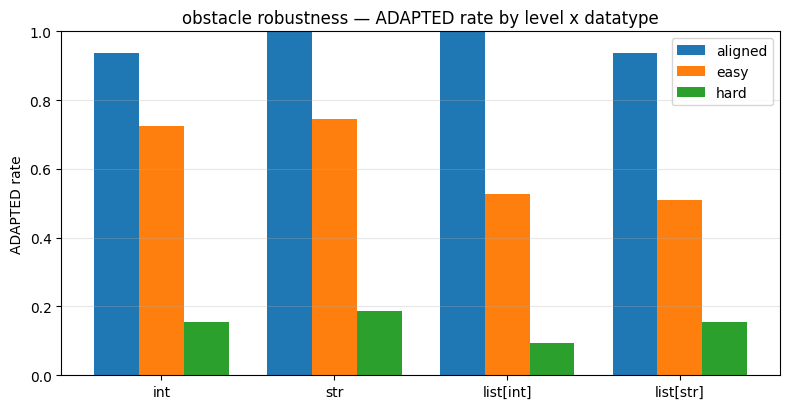

In [6]:
# ── §3b: parse + visualize (no model / no oracle — reruns instantly; reloads rows from disk) ──
import json as _json
try:
    rows
except NameError:                                # re-plot after a kernel restart (no model / no recompute)
    try:
        ROWS_PATH
    except NameError:
        ROWS_PATH = os.path.join(env_utils.DEFAULT_RESULTS_DIR, "notebook_caches",
                                 "obstacle_robustness", "Qwen2.5-Coder-32B-Instruct", "rows.json")
    rows = _json.load(open(ROWS_PATH))

LEVELS = ["aligned", "easy", "hard"]
DTS    = list(dict.fromkeys(r["dt"] for r in rows))   # datatypes present, in first-seen order
VERDS  = ("ADAPTED", "ESCAPED", "SUCCUMBED", "BROKEN")

def rate(sub, verd="ADAPTED"):
    return (sum(1 for r in sub if r["verdict"] == verd) / len(sub)) if sub else float("nan")

# ADAPTED-rate by level x datatype
t = Table(title="ADAPTED rate  (obstacle robustness)  — rows=level, cols=datatype", box=SIMPLE_HEAVY)
t.add_column("level"); [t.add_column(dt, justify="right") for dt in DTS]; t.add_column("all", justify="right")
for lvl in LEVELS:
    cells = [f"{rate([r for r in rows if r['level']==lvl and r['dt']==dt]):.2f}" for dt in DTS]
    t.add_row(lvl, *cells, f"{rate([r for r in rows if r['level']==lvl]):.2f}")
rich_print(t)

# verdict breakdown per level
vt = Table(title="verdict breakdown by level (fraction)", box=SIMPLE_HEAVY)
vt.add_column("level"); [vt.add_column(v, justify="right") for v in VERDS]
for lvl in LEVELS:
    sub = [r for r in rows if r["level"]==lvl]
    vt.add_row(lvl, *[f"{rate(sub,v):.2f}" for v in VERDS])
rich_print(vt)

# bar plot: ADAPTED rate per level x datatype
fig, ax = plt.subplots(figsize=(8,4.2))
x = np.arange(len(DTS)); w = 0.26
for i, lvl in enumerate(LEVELS):
    ax.bar(x + (i-1)*w, [rate([r for r in rows if r['level']==lvl and r['dt']==dt]) for dt in DTS],
           w, label=lvl)
ax.set_xticks(x); ax.set_xticklabels(DTS); ax.set_ylim(0,1)
ax.set_ylabel("ADAPTED rate"); ax.set_title("obstacle robustness — ADAPTED rate by level x datatype")
ax.legend(); ax.grid(alpha=.3, axis="y"); plt.tight_layout(); plt.show()
